In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("../data/processed/sales_cleaned.csv")
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

df.head()

,OrderID,OrderDate,Product,Category,Region,SalesChannel,Quantity,UnitPrice,Discount,Revenue,Cost,Profit,CustomerID,GrossSales,Year,Month,MonthName,Quarter
0,ORD02605,2022-01-01,Headphones,Accessories,West,Online,3,2543.81,20,6105.14,4240.18,1864.96,CUST0086,7631.43,2022,1,Jan,2022Q1
1,ORD04726,2022-01-01,Printer,Electronics,Central,Retail,1,9924.79,15,8436.07,7660.75,775.32,CUST0940,9924.79,2022,1,Jan,2022Q1
2,ORD04152,2022-01-01,Keyboard,Accessories,Central,Retail,1,1805.94,5,1715.64,1010.31,705.33,CUST0458,1805.94,2022,1,Jan,2022Q1
3,ORD02903,2022-01-01,Smartphone,Electronics,North,Distributor,6,25891.81,0,155350.86,111162.80,44188.06,CUST0055,155350.86,2022,1,Jan,2022Q1
4,ORD04130,2022-01-02,Printer,Electronics,South,Online,10,10263.78,0,102637.80,74142.92,28494.88,CUST0052,102637.80,2022,1,Jan,2022Q1


In [2]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate OrderIDs:", df["OrderID"].duplicated().sum())

print("\nSummary statistics:")
display(df.describe().round(2))

Dataset shape: (5000, 18)

Data types:
OrderID                    str
OrderDate       datetime64[us]
Product                    str
Category                   str
Region                     str
SalesChannel               str
Quantity                 int64
UnitPrice              float64
Discount                 int64
Revenue                float64
Cost                   float64
Profit                 float64
CustomerID                 str
GrossSales             float64
Year                     int64
Month                    int64
MonthName                  str
Quarter                    str
dtype: object

Missing values:
OrderID         0
OrderDate       0
Product         0
Category        0
Region          0
SalesChannel    0
Quantity        0
UnitPrice       0
Discount        0
Revenue         0
Cost            0
Profit          0
CustomerID      0
GrossSales      0
Year            0
Month           0
MonthName       0
Quarter         0
dtype: int64

Duplicate OrderIDs: 0

Summary sta

,OrderDate,Quantity,UnitPrice,Discount,Revenue,Cost,Profit,GrossSales,Year,Month
count,5000,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,2024-01-10 12:14:58.560000,3.18,15258.72,7.80,45158.54,36963.70,8194.84,48958.86,2023.49,6.94
min,2022-01-01 00:00:00,1.00,1710.78,0.00,1395.62,970.79,-27311.87,1710.83,2022.00,1.00
25%,2022-12-25 00:00:00,1.00,2478.87,0.00,7216.88,4244.22,1967.36,7698.66,2022.00,4.00
50%,2024-01-01 00:00:00,3.00,10023.36,5.00,21430.78,17370.53,4163.80,24116.31,2024.00,7.00
75%,2024-12-29 00:00:00,4.00,24182.71,10.00,54527.35,43698.19,9755.71,59732.28,2024.00,10.00
max,2025-12-31 00:00:00,10.00,68246.29,20.00,673542.70,527685.92,147766.89,682020.70,2025.00,12.00
std,NaN,2.24,16979.01,6.28,68810.95,59025.67,11618.39,74279.20,1.12,3.45


In [3]:
monthly_sales = (
    df.set_index("OrderDate")
    .resample("MS")["Revenue"]
    .sum()
    .reset_index()
)

fig = px.line(
    monthly_sales,
    x="OrderDate",
    y="Revenue",
    markers=True,
    title="Monthly Revenue Trend"
)

fig.show()

In [4]:
product_sales = (
    df.groupby("Product", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
)

fig = px.bar(
    product_sales,
    x="Product",
    y="Revenue",
    color="Revenue",
    title="Total Revenue by Product"
)

fig.show()

In [5]:
region_sales = (
    df.groupby("Region", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
)

fig = px.bar(
    region_sales,
    x="Region",
    y="Revenue",
    color="Region",
    title="Total Revenue by Region"
)

fig.show()

In [6]:
category_profit = (
    df.groupby("Category", as_index=False)["Profit"]
    .sum()
    .sort_values("Profit", ascending=False)
)

fig = px.bar(
    category_profit,
    x="Category",
    y="Profit",
    color="Category",
    title="Total Profit by Category"
)

fig.show()

In [7]:
fig = px.histogram(
    df,
    x="Revenue",
    nbins=40,
    title="Distribution of Transaction Revenue"
)

fig.show()

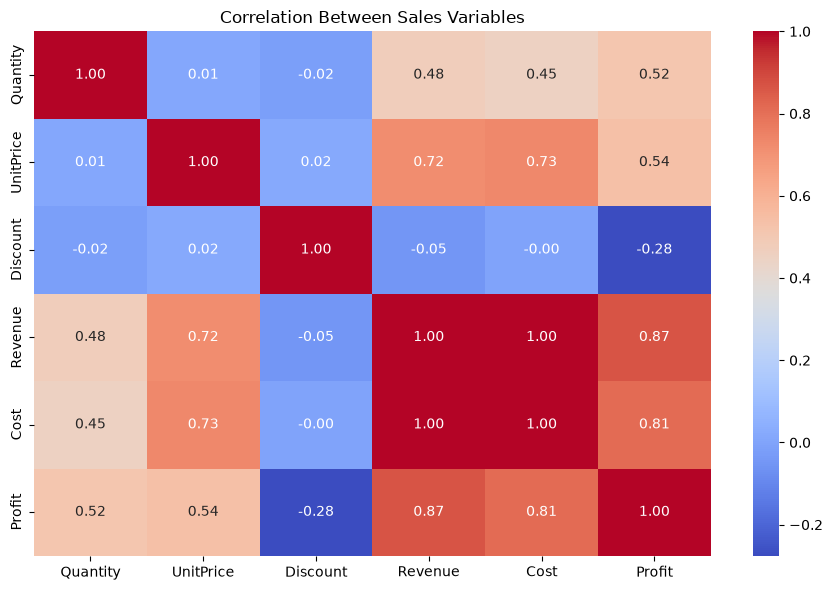

In [8]:
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "Discount",
    "Revenue",
    "Cost",
    "Profit"
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Sales Variables")
plt.tight_layout()
plt.show()